In [3]:
import numpy as np
import matplotlib.pyplot as plt

# Add files up one level to the path
import sys
sys.path.append("..")

import jlinops

from matplotlib.backends.backend_pdf import PdfPages

from scipy.linalg import qr, qr_insert
from scipy.integrate import odeint
import scipy.optimize as op
import scipy.sparse as sps
from scipy import linalg as la
from scipy.optimize import root


from fastprogress import progress_bar

import warnings

import scipy.optimize as op
from scipy.sparse.linalg import svds
from scipy.linalg import null_space

import scipy.sparse as sps
from scipy.fft import dct, idct

from scipy.optimize import brentq


from skimage.metrics import structural_similarity




# Try to import matlab.engine
try:
    import matlab.engine
except:
    pass # assume we don't need it
    # raise Exception("Error with matlab.engine, make sure it is installed correctly.")


from trips.utilities.weights import smoothed_holder_weights
from trips.utilities.decompositions import golub_kahan

from trips.utilities.reg_param.discrepancy_principle import discrepancy_principle
from trips.utilities.reg_param.gcv import generalized_crossvalidation

from regparam_selection import mgcv, dp_cubic, matlab_gcv
from regparam_selection import optimal_regparam, optimal_regparam_ssim


In [4]:
class FKSolver:
    """Implements a generic GKS solver for problems of the form:

    If noise_var is provided, then the problem solved is 
        argmin_x  (1/noise_var)*|| A x - b ||_2^2 + \lambda || L x ||_q^q.

    """

    def __init__(self, A, L, b, noise_var=None, Lpinv_factory=None, K=None, img_shape=None):

        # Bind
        self._A = A
        self.L = L
        self._b = b
        self.noise_var = noise_var
        self.Lpinv_factory = Lpinv_factory
        self.K = K
        self.n = A.shape[1]
        self.m = A.shape[0]
        self.k = L.shape[0]
        self.img_shape = img_shape

        # Whiten?
        if self.noise_var is not None:
            self.noise_stdev = np.sqrt(self.noise_var)
            self.A = (1.0/self.noise_stdev)*self._A
            self.b = (1.0/self.noise_stdev)*self._b
        else:
            self.noise_stdev = None
            self.A = self._A
            self.b = self._b


    def update_weights(self, x, weight_params):

        raise NotImplementedError


    def build_initial_basis(self, dim):
        """
        Builds the initial basis.
        """

        Atb = self.A.T @ self.b

        V = np.zeros((self.n, dim))
        V[:,0] = Atb
        tmp = Atb.copy()
        for j in range(1,dim):
            tmp = self.A.T @ (self.A @ tmp)
            V[:,j] = tmp.copy()

        # V = np.random.normal(size=(self.n, 5))

        # Orthogonalize
        qr_fac = np.linalg.qr(V)
        V = qr_fac.Q

        return V
    

    def build_restarted_basis(self, dim, x, w, lambdah):
        """
        Builds the restarted basis.
        """
        Atb = self.A.T @ self.b

        V = np.zeros((self.n, dim))
        V[:,0] = Atb
        tmp = Atb.copy()
        for j in range(1,dim):
            tmp = (self.A.T @ (self.A @ tmp)) + lambdah*(self.L.T @ (w * (w * (self.L @ tmp ) ) ) )
            V[:,j] = tmp.copy()

        V = np.column_stack([V, x])

        # Orthogonalize
        qr_fac = np.linalg.qr(V)
        V = qr_fac.Q

        return V
    

    def build_priorconditioning_initial_basis(self, Atilde, c, lambdah, dim):
        """
        Builds the initial basis for the priorconditioned algorithm.
        """

        Atildetc = Atilde.T @ c

        V = np.zeros((Atilde.shape[1], dim))
        V[:,0] = Atildetc
        tmp = Atildetc
        for j in range(1,dim):
            # print(j)
            # print(tmp)
            tmp = Atilde.T @ (Atilde @ tmp)
            #tmp = Atilde.T @ (Atilde @ tmp) + lambdah*tmp
            tmp = tmp/np.linalg.norm(tmp)
            V[:,j] = tmp.copy()

        # V = np.random.normal(size=(self.n, 5))

        # Orthogonalize
        qr_fac = np.linalg.qr(V)
        V = qr_fac.Q

        return V
    

    def select_regparam(self, Q_A, R_A, Q_L, R_L, b, regparam, c=None, eng=None, xker=None, x_true=None, V=None, priorconditioning=False, Lopinv=None, **regparam_kwargs):
        """Selects regularization parameter for the projected problem.
        """

        if c is None:
            c = b

        # Select new regularization parameter
        if regparam == "mgcv": # Jonathan's MGCV method
            proposed_lambdah = mgcv(Q_A, R_A, R_L, c, **regparam_kwargs)
        elif regparam == "dp": # Trips-Py dp
            proposed_lambdah = discrepancy_principle(Q_A, R_A, R_L, c, delta=np.sqrt(self.m), explicitProj=True, **regparam_kwargs)
        elif regparam == 'gcv': # Trips-Py gcv
            proposed_lambdah = generalized_crossvalidation(Q_A, R_A, R_L, c, **regparam_kwargs)
        elif regparam == "dp2": # Jonathan's 2nd-order DP code. Requires 2 LS solves per iteration.
            shift = np.linalg.norm( b -  ( Q_A @ (Q_A.T @ b) ), ord=2 )**2 # needed for calculation w.r.t. full-scale objective
            # Hacky try-except block since code is not completely debugged for small \beta!
            try:
                data = dp_quadratic(R_A, R_L, Q_A.T @ c, noise_var=1.0, shift=shift, m=len(b), beta0=self.beta0, **regparam_kwargs)
            except:
                # If it didn't work with initializing beta0, try again without initializing it (defaults to beta0 very small). 
                data = dp_quadratic(R_A, R_L, Q_A.T @ c, noise_var=1.0, shift=shift, m=len(b), beta0=None, **regparam_kwargs)
                #pass
            proposed_lambdah = data["lambda"]
            self.beta0 = 1.0/proposed_lambdah
        elif regparam == "dp3": # Jonathan's 3rd-order DP code. Requires 3 LS solves per iteration.
            shift = np.linalg.norm( b -  ( Q_A @ (Q_A.T @ b) ), ord=2 )**2 # needed for calculation w.r.t. full-scale objective
            # Hacky try-except block since code is not completely debugged for small \beta!
            try:
                data = dp_cubic(R_A, R_L, Q_A.T @ c, noise_var=1.0, shift=shift, m=len(b), beta0=self.beta0, **regparam_kwargs)
            except:
                # If it didn't work with initializing beta0, try again without initializing it (defaults to beta0 very small). 
                data = dp_cubic(R_A, R_L, Q_A.T @ c, noise_var=1.0, shift=shift, m=len(b), beta0=None, **regparam_kwargs)
                #pass
            proposed_lambdah = data["lambda"]
            self.beta0 = 1.0/proposed_lambdah
        elif regparam == "matlab_gcv": # MATLAB GCV code
            proposed_lambdah = matlab_gcv( R_A, R_L, Q_A.T @ c, eng=eng, **regparam_kwargs)
        elif regparam == "optimal":
            assert x_true is not None, "Must provide x_true to use optimal regparam method."
            assert V is not None, "Must pass V to use optimal regparam method."
            if not priorconditioning:
                proposed_lambdah = optimal_regparam(R_A, R_L, Q_A, Q_L, self.b, V, x_true, **regparam_kwargs)
            else:
                assert xker is not None, "Must pass xker."
                proposed_lambdah = optimal_regparam(R_A, R_L, Q_A, Q_L, c, V, x_true, Lopinv=Lopinv, xker=xker, **regparam_kwargs)
        elif regparam == "optimal_ssim":
            assert x_true is not None, "Must provide x_true to use optimal regparam method."
            assert V is not None, "Must pass V to use optimal regparam method."
            if not priorconditioning:
                proposed_lambdah = optimal_regparam_ssim(R_A, R_L, Q_A, Q_L, self.b, V, x_true, **regparam_kwargs)
            else:
                assert xker is not None, "Must pass xker."
                proposed_lambdah = optimal_regparam_ssim(R_A, R_L, Q_A, Q_L, c, V, x_true, Lopinv=Lopinv, xker=xker, **regparam_kwargs)
        elif not isinstance(regparam, str): # hope that regparam is a scalar
            proposed_lambdah = regparam
        else:
            raise NotImplementedError

        return proposed_lambdah
    

    def compress_basis(self, V, R_A, R_L, x, Q_A, kmin, lambdah):
        """Compresses the basis using TSVD approach.
        """

        # Make H matrix
        print(R_A.shape)
        print(R_L.shape)
        H = np.vstack([R_A, np.sqrt(lambdah)*R_L ])
        print(H.shape)

        # Truncated SVD
        # _, _, Wh = svds(H, k=kmin-1)
        # W = Wh.T
        W = compute_V_matrix_k(H, kmin-1 )

        # Get new basis
        Vtilde = V @ W
        #assert np.linalg.norm( (Vtilde.T @ Vtilde) - np.eye(Vtilde.shape[1]) ) < 1e-10, "New basis is not a basis"
        qr_fac = np.linalg.qr(Vtilde)
        Vtilde = qr_fac.Q

        #print(np.linalg.norm( (Vtilde.T @ Vtilde) - np.eye(Vtilde.shape[1]) ))
        assert np.linalg.norm( (Vtilde.T @ Vtilde) - np.eye(Vtilde.shape[1]) ) < 1e-10, "New basis is not a basis"

        xnew = x -  Vtilde @ (Vtilde.T @ x)
        xnew /= np.linalg.norm(xnew)
        V = np.column_stack((Vtilde, xnew))
        assert np.linalg.norm( (V.T @ V) - np.eye(V.shape[1]) ) < 1e-10, "New basis is not a basis"

        # Orthogonalize
        qr_fac = np.linalg.qr(V)
        V = qr_fac.Q

        return V
    

    def solve(self, n_iter=25, x0=None, regparam=None, x_true=None, lambdah0=None, weight_params=None):

        valid_regparams = ["dp3", "dp"]
        assert regparam or np.isscalar(regparam), f"Invalid choice of regparam, must be scalar or one of {valid_regparams}"
        assert self.Lpinv_factory is not None, "Must pass Lpinv_factory at instantiation..."
        assert self.Lpinv_factory is not None, "Must pass Lpinv_factory at instantiation..."

        # Tracking
        tot_matvec_A = 0
        tot_matvec_L = 0 
        lambda_history = []
        residual_history = []
        rre_history = []
        ssim_history = []
        cond_ests = []
        dp_ineq_lhs = []
        dp_ineq_rhs = []
        dp_ineq_chs = []

        # Initialize lambdah? Doesn't always actually affect anything, depending on the weight updates...
        if lambdah0 is None:
            #lambdah = 1.0
            lambdah = regparam
        else:
            lambdah = lambdah0

        # Initialization
        if x0 is None:
            x = self.A.T @ self.b
            tot_matvec_A += 1
        else:
            x = x0

        # Metrics
        if x_true is not None:
            x_true_norm = np.linalg.norm(x_true)
            rre_history.append( np.linalg.norm(x - x_true)/x_true_norm )
            if self.img_shape is None:
                ssim_history.append( structural_similarity( x, x_true, data_range=(np.amax(x_true) - np.amin(x_true) ), gaussian_weights=True, sigma=1.5, use_sample_covariance=False ) )
            else:
                ssim_history.append( structural_similarity( x.reshape(self.img_shape), x_true.reshape(self.img_shape), data_range=(np.amax(x_true) - np.amin(x_true) ), gaussian_weights=True, sigma=1.5, use_sample_covariance=False ) )

        
        # Get initial weights and pseudoinverses
        w = self.update_weights(self.L @ x, lambdah, weight_params)
        Lpinv = self.Lpinv_factory(w)
        if self.K is not None:
            AKpinv = jlinops.QRPinvOperator( jlinops.MatrixLinearOperator(self.A.matmat(self.K.A)) )
            Lopinv = ( jlinops.IdentityOperator( (self.A.shape[1], self.A.shape[1])  ) - self.K @ (AKpinv @ self.A)  ) @ Lpinv
            Atilde = self.A @ Lopinv
        else:
            Atilde = self.A @ Lpinv
            Lopinv = Lpinv

        if self.K is not None:
            xker = self.K @ (AKpinv @ self.b)
            Axker = self.A @ xker
            c = self.b - Axker
            tot_matvec_A += 1
        else:
            xker = np.zeros(self.A.shape[1])
            c = self.b


        # Initial calculations
        #xinc = self.L @ (Lopinv @ ( self.L @ x ))
        #r = c - Atilde @ xinc
        r = c
        #r = self.b - self.A @ x
        u  = r / np.linalg.norm(r)
        U = u[:,None]


        for i in range(n_iter):

            print(f"Starting iteration {i}")
            
            ### Get new weights

            # Get initial weights and pseudoinverses
            w = self.update_weights(self.L @ x, lambdah, weight_params)
            Lpinv = self.Lpinv_factory(w)
            if self.K is not None:
                AKpinv = jlinops.QRPinvOperator( jlinops.MatrixLinearOperator(self.A.matmat(self.K.A)) )
                Lopinv = ( jlinops.IdentityOperator( (self.A.shape[1], self.A.shape[1])  ) - self.K @ (AKpinv @ self.A)  ) @ Lpinv
                Atilde = self.A @ Lopinv
            else:
                Atilde = self.A @ Lpinv
                Lopinv = Lpinv

        
            ### Iteration

            vbar = self.A.T @ u
            if i == 0:
                v = vbar
            else:
                v = vbar - (V @ (V.T @ vbar))
            v = v/np.linalg.norm(v)
            
            if i == 0:
                V = v[:,None]
            else:
                V = np.column_stack((V,v))

            z = Lopinv @ (Lopinv.T @ v)
            if i == 0:
                Z = z[:,None]
                AZ = (self.A @ z)[:,None]
            else:
                Z = np.column_stack((Z,z))
                #AZ = self.A @ Z
                AZ = np.column_stack((AZ, self.A @ z))

            ubar = self.A @ z
            u = ubar - (U @ (U.T @ ubar))
            u = u/np.linalg.norm(u)
            U = np.column_stack((U, u))
            
            #assert np.isscalar(regparam)

            # Other calculations
            H = U.T @ AZ
            W = sps.diags(w)
            N = W @ (self.L @ Z)
            e1 = np.zeros(H.shape[0])
            e1[0] = 1.0
            (Q_N, R_N) = la.qr(N, mode='economic') 


            # Use root-finder to find lambdah (full-scale problem)
            # eta = 1.01
            # def eval_x_lambda(_lambdah):
            #     y, _ , _, svals = np.linalg.lstsq(np.vstack( (H, np.sqrt(_lambdah) * N) ), np.concatenate(( np.linalg.norm(c)*e1,  np.zeros((N.shape[0],)))),rcond=-1)
            #     return (Z @ y)

            # def root_finding_func(_lambdah):
            #     xsol = eval_x_lambda(_lambdah)
            #     return (np.linalg.norm( (H @ xsol) - np.linalg.norm(c)*e1  )**2) - ( eta*len(c) - (np.linalg.norm( c - ( U @ (U.T @ c) ) )**2) )
            
            # # Use root-finder to find lambdah (full-scale problem)
            eta = 1.01
            def eval_x_lambda(_log_lambdah):
                y, _ , _, svals = np.linalg.lstsq(np.vstack( (H, np.sqrt(np.exp(_log_lambdah)) * N) ), np.concatenate(( np.linalg.norm(c)*e1,  np.zeros((N.shape[0],)))),rcond=-1)
                return (Z @ y) + xker

            def root_finding_func(_log_lambdah):
                xsol = eval_x_lambda(_log_lambdah)
                return (np.linalg.norm( (self.A @ xsol) - self.b  )**2) - (eta**2)*len(c)
            
            try:
                root_result = brentq(root_finding_func, -14, 7)
                lambdah = np.exp(root_result)
            except:
                lambdah = 1e-14
            #lambdah_res = root(root_finding_func, 1.0)
            #lambdah = lambdah_res.x[0]
            print(lambdah)
            lambda_history.append(lambdah)

            # Solve for fixed lambda
            y, _ , _, svals = np.linalg.lstsq(np.vstack( (H, np.sqrt(lambdah) * N) ), np.concatenate(( np.linalg.norm(c)*e1,  np.zeros((N.shape[0],)))),rcond=-1)

            # Recover full solution
            x = Z @ y # Project back onto z space
            if self.K is not None:
                #print(Lopinv.shape)
                #print(x.shape)
                #print(xker.shape)
                xfull = x + xker
                #xfull = (Lopinv @ x) + xker # Project back onto x space
            else:
                xfull = x + xker
                #xfull = Lpinv @ x


            # Metrics
            if x_true is not None:
                x_true_norm = np.linalg.norm(x_true)
                rre_history.append( np.linalg.norm(xfull - x_true)/x_true_norm )
                if self.img_shape is None:
                    ssim_history.append( structural_similarity( xfull, x_true, data_range=(np.amax(x_true) - np.amin(x_true) ), gaussian_weights=True, sigma=1.5, use_sample_covariance=False ) )
                else:
                    ssim_history.append( structural_similarity( xfull.reshape(self.img_shape), x_true.reshape(self.img_shape), data_range=(np.amax(x_true) - np.amin(x_true) ), gaussian_weights=True, sigma=1.5, use_sample_covariance=False ) )


        # Package data
        data = {
            "x": xfull,
            "V": V,
            "U": U,
            "H": H,
            "Z": Z,
            "w": w,
            "lambda_history": np.asarray(lambda_history),
        }

        if x_true is not None:
            data["rre_history"] = np.asarray(rre_history)
            data["ssim_history"] = np.asarray(ssim_history)

        return data






## Specific update formulas

def conditional_mode_ode_rhs(varphi, z, r):
        """RHS of the ODE used for updating theta.
        """
        
        dvarphidz = (2*z*varphi)/((2*(r**2)*((varphi)**(r+1))) + (z**2))

        return dvarphidz



def theta_update(Lx, r, beta, vartheta):
    """Returns the theta-update IAS.
    """

    eta = r*beta - 1.5
    initial_value = (eta/r)**(1/r)

    # Rescale
    z = np.abs(  ( Lx )  / np.sqrt(vartheta) )

    # If r = 1, use exact formula
    if abs(r - 1) < 1e-5:    
            # print("Using exact formula for r = 1")
            xi = 0.5*( eta + np.sqrt( (eta**2) +  2*(z**2)  ) )
            new_theta = vartheta*xi
            
            return new_theta

    elif abs(r + 1) < 1e-5:
            
            # print("Using exact formula for r = -1")
            
            k = beta + 1.5
            xi = (1/(2*k)) * ( (z**2) + 2 )
            new_theta = vartheta*xi
            
            return new_theta

    # Otherwise, solve using the ODE method
    else:
        
        #print("Using ODE method")
        
        final_times = z

        # Sort the final times
        argsort = final_times.argsort()
        final_times_sorted = final_times[argsort]

        # We need to prepend zero to this for the solver
        final_times_sorted = np.insert(final_times_sorted, 0, 0)

        # Now solve the ODE
        ode_sol = odeint(conditional_mode_ode_rhs,
                            np.atleast_1d(initial_value), 
                            final_times_sorted,
                            args=(r,) # r parameter
                        )

        # Reshape and drop the first value corresponding to the dummy initial value
        ode_sol = ode_sol[1:,0]

        # Now back out the updated value of the hyper-parameter
        xi = np.zeros_like(final_times)
        xi[argsort] = ode_sol
        new_theta = vartheta*xi

        return new_theta







class MMFK(FKSolver):

    def __init__(self, A, L, b, noise_var=None, Lpinv_factory=None, K=None, img_shape=None):

        super().__init__(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)


    def update_weights(self, Lx, lambdah, weight_params):
        
        w = np.sqrt( smoothed_holder_weights( Lx, epsilon=weight_params["epsilon"], p=weight_params["q"] ) )

        return w



class IASFK(FKSolver):

    def __init__(self, A, L, b, noise_var=None, Lpinv_factory=None, K=None, img_shape=None):

        super().__init__(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)


    def update_weights(self, Lx, lambdah, weight_params):

        theta = theta_update( Lx/np.sqrt(1.0/lambdah), weight_params["hyperpr_r"], weight_params["hyperpr_beta"], 1.0)
        w = 1.0/np.sqrt(theta)

        return w
    


class VanillaFK(FKSolver):

    def __init__(self, A, L, b, noise_var=None, Lpinv_factory=None, K=None, img_shape=None):

        super().__init__(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K, img_shape=img_shape)


    def update_weights(self, Lx, lambdah, weight_params):

        return np.ones_like(Lx)
    

# Test problem

In [5]:
n = 1000
ground_truth = 5*np.ones(n)
ground_truth[:250] = 3
ground_truth[250:400] = 6
ground_truth[400:625] = 1
ground_truth[625:825] = 3
ground_truth[825:] = 5
grid = np.arange(n)

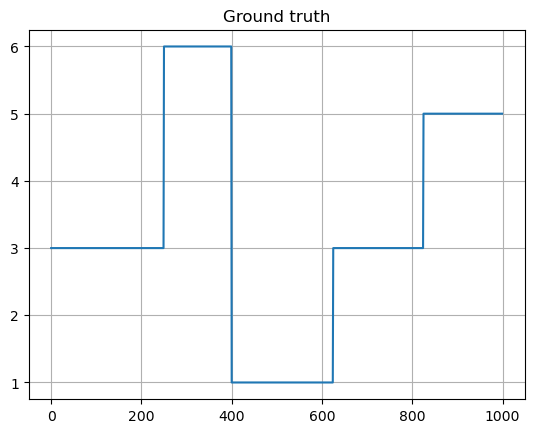

In [6]:
plt.plot(ground_truth)
plt.title("Ground truth")
plt.grid()
plt.show()

In [7]:
# Black box operator for DCT
from jlinops import _CustomLinearOperator

class DCT1D(_CustomLinearOperator):
    """Implements a 1D dct
    """

    def __init__(self, n, type=2, norm="ortho", device="cpu"):
        
        self.type = type
        self.n_size = n
        self.norm = norm


        def _matvec(x):
            return dct(np.squeeze(x), type=self.type, norm=self.norm)
        
        def _rmatvec(x):
            return idct(np.squeeze(x), type=self.type, norm=self.norm)
        
        super().__init__( (n,n), _matvec, _rmatvec, device=device, dtype=None)


In [8]:
F = DCT1D(n)
#F_explicit = jlinops.black_box_to_dense(F)

In [9]:
# # Random undersampling
# np.random.seed(0)
# mask = np.random.binomial(1, 0.8, size=n)
# P = jlinops.Subsampling1DOperator(mask)

# Only first 100 components
mask = np.ones(n)
mask[50:] = 0.0
P = jlinops.Subsampling1DOperator(mask)

In [10]:
# Generate synthetic data
np.random.seed(0)
A = P @ F
b_true = A @ ground_truth
noise_vec = np.random.normal(size=A.shape[0])
noise_vec /= np.linalg.norm(noise_vec)
noise_level_sigma = 0.03
noise_vec *= noise_level_sigma*np.linalg.norm(b_true)
#noise_sigma = 0.01*np.amax(b_true)
#noise_var = noise_sigma**2
noise_var = ( (noise_level_sigma*np.linalg.norm(b_true) )**2 ) / A.shape[0]
b = b_true + noise_vec
#b =  b_true + noise_sigma*np.random.normal(size=A.shape[0])

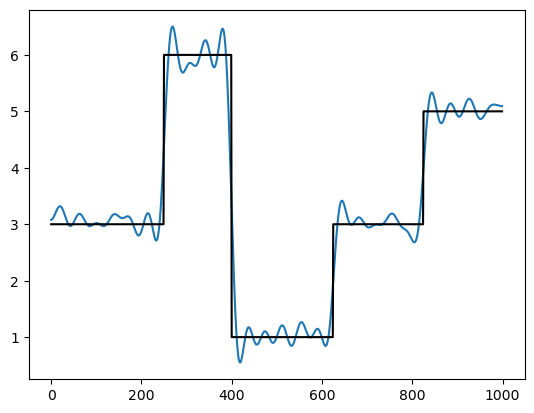

In [11]:
# Inverse DCT reconstruction
plt.plot(A.T @ b)
plt.plot(ground_truth, color="k")
plt.show()

# Setup prior

In [12]:
Lmat, Kmat = jlinops.first_order_derivative_1d(n, boundary="none")
L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator
Kmat = Kmat/np.linalg.norm(Kmat)

# Lmat, Wmat = jlinops.first_order_derivative_1d(n, boundary="zero")
# L = jlinops.MatrixLinearOperator(Lmat) # Cast sparse matrix R as a linear operator


# Pseudoinverse factory
# def Lpinv_factory(wr):
#     Ltilde = jlinops.MatrixLinearOperator( sps.diags(wr) @ Lmat)
#     return jlinops.BandedCholeskyPinvOperator(Ltilde, delta=1e-14)

_Lpinv = jlinops.MatrixLinearOperator(np.linalg.pinv(L.A.toarray()))
Lpinv_factory = lambda wr: _Lpinv @ jlinops.MatrixLinearOperator(sps.diags(1.0/wr))

K = jlinops.MatrixLinearOperator(Kmat)
K

#err_norm_sq = len(b) # in expectation

# Build solvers

q = 1.0
epsilon = 1e-3
mmgks_weight_params = {
    "q": q,
    "epsilon": epsilon,
}

#gks_solver = VanillaGKS(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)
mmfk_solver = MMFK(A, L, b, noise_var=noise_var, Lpinv_factory=Lpinv_factory, K=K)

AK = A @ K.A
AKpinv = jlinops.QRPinvOperator(AK)
xker = K @ (AKpinv @ b)

# Run the solver

In [13]:
n_its = 50
method = 1e2

pdata = mmfk_solver.solve(n_iter=n_its, x0=None, lambdah0=None,
                                                 regparam=method, x_true=ground_truth, weight_params=mmgks_weight_params, 
                                                #  regparam_kwargs={"eta":1.01},
                                                #  lambdah_min=1e-7, lambdah_max=1e7,
                                                #  init_dim=5
                                                 )

Starting iteration 0
1e-14
Starting iteration 1
1e-14
Starting iteration 2
1e-14
Starting iteration 3
1e-14
Starting iteration 4
1e-14
Starting iteration 5
1e-14
Starting iteration 6
2.9973778780546705
Starting iteration 7
8.328980768633185
Starting iteration 8
9.559838451072334
Starting iteration 9
10.413457344953153
Starting iteration 10
10.83064657186492
Starting iteration 11
11.063095939980766
Starting iteration 12
11.037140926455082
Starting iteration 13
10.998817476682733
Starting iteration 14
11.106661999359263
Starting iteration 15
11.849353938793792
Starting iteration 16
11.51121231075703
Starting iteration 17
11.267109443765927
Starting iteration 18
11.14060510737292
Starting iteration 19
11.09047643203819
Starting iteration 20
11.15085492103306
Starting iteration 21
11.118991598109798
Starting iteration 22
11.116897328162775
Starting iteration 23
10.947833072567965
Starting iteration 24
11.075878664937267
Starting iteration 25
11.142382852186703
Starting iteration 26
11.0151

In [14]:
np.linalg.norm( ( pdata["U"] @ pdata["H"] ) - ( mmfk_solver.A @ pdata["Z"] ) )

22.373426475393305

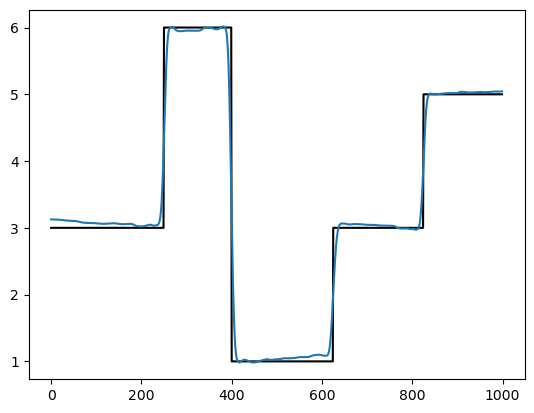

In [15]:
plt.plot(ground_truth, color="k")
plt.plot(pdata["x"])
plt.show()

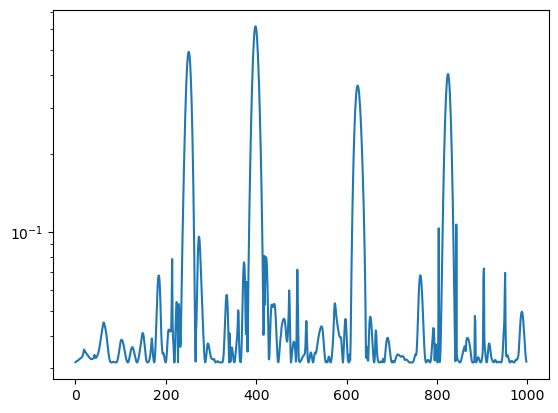

In [494]:
#plt.plot(ground_truth, color="k")
plt.semilogy(1.0/pdata["w"])
plt.show()

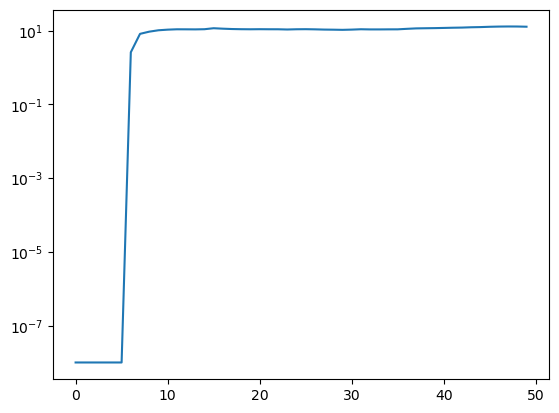

In [495]:
plt.semilogy(pdata["lambda_history"])
plt.show()

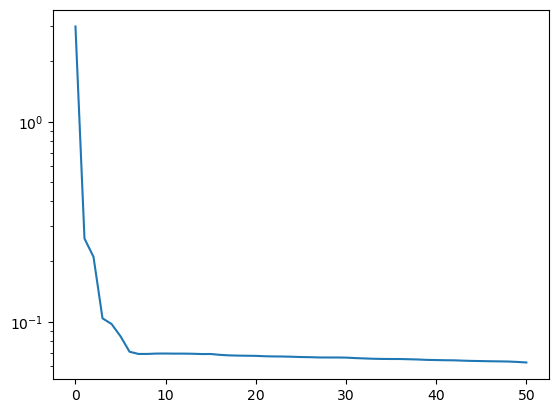

In [493]:
plt.semilogy(pdata["rre_history"])
plt.show()

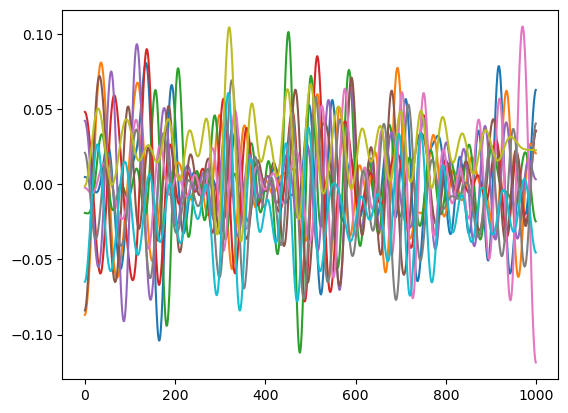

In [501]:
for j in range(40,50):
    plt.plot(pdata["V"][:,j])

plt.show()

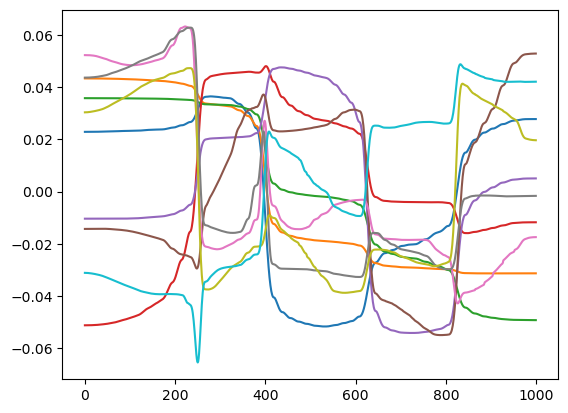

In [506]:
for j in range(10):
    plt.plot(  pdata["Z"][:,j]/np.linalg.norm(pdata["Z"][:,j])  )

In [468]:
np.diag(pdata["Z"].T @ pdata["Z"])

array([4.15478908e+06, 6.19846144e+05, 1.02176038e+06, 1.63544742e+04,
       1.77579013e+04, 1.62539386e+03, 5.43934237e+02, 1.64675750e+03,
       5.02704164e+02, 7.70497765e+02, 8.58732107e+02, 1.18825153e+02,
       1.83235464e+03, 4.99064799e+02, 2.61434532e+02, 1.19760284e+02,
       1.56208699e+01, 2.36989487e+01, 1.06789178e+02, 5.34941454e+01])

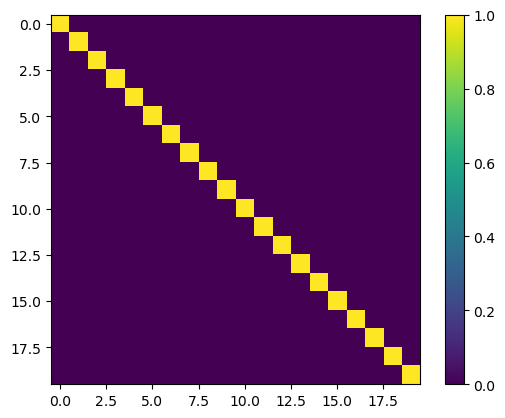

In [469]:
plt.imshow(pdata["V"].T @ pdata["V"])
plt.colorbar()
plt.show()

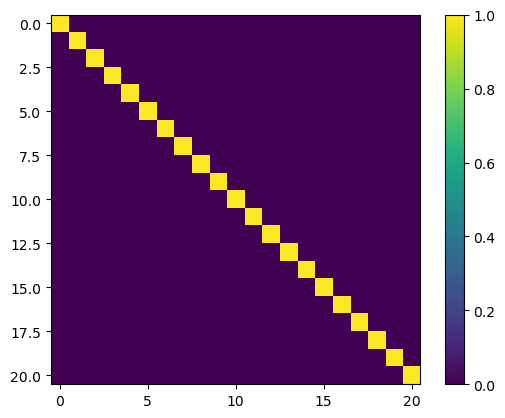

In [320]:
plt.imshow(pdata["U"].T @ pdata["U"])
plt.colorbar()
plt.show()

In [321]:
pdata["H"]

array([[ 3.35960476e+03,  3.16392935e+02, -6.78601699e+01,
         2.54118777e+00, -4.43198554e+01,  1.06302391e+01,
        -1.08589828e+01,  1.59388290e+01,  1.22423181e+01,
         4.41784657e+00, -8.47612045e+00,  1.12773067e+00,
         1.19827086e+01,  5.49182224e+00, -8.50747216e-01,
         7.16478729e+00,  6.48035516e+00,  2.99656475e-01,
        -2.44093476e-01,  6.77144789e-01],
       [ 2.28691209e+03,  1.15503814e+03,  1.11082961e+03,
        -1.73174063e+02, -2.27497161e+01, -8.65090113e+00,
         3.12458788e+01,  7.07018407e+01,  5.26299240e+01,
        -2.84826910e+00, -3.25067149e+01, -1.42503034e+00,
         2.37060222e+01,  2.14258529e+00,  1.25748046e+01,
         4.66070655e+01,  2.94302481e+01,  1.99397493e+01,
         2.21188849e+01,  1.16562408e+01],
       [-1.18532077e-12,  1.01274853e+03,  1.64488777e+03,
         1.04046999e+02,  8.96921252e+01, -2.57331525e+00,
         1.33383850e+01,  2.31565065e+01, -2.23159581e+00,
        -1.43346586e+01,  4.9